In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv('../data/processed/donnees_economiques_maroc.csv', index_col=0)
df.head()

,pib,inflation_pct,chomage_pct
2000,4.301746e+10,1.894635,13.58
2001,4.383148e+10,0.619802,12.46
2002,4.707719e+10,2.795620,11.59
2003,5.802936e+10,1.167734,11.92
2004,6.611415e+10,1.493444,10.83


In [3]:
df['pib_lag1'] = df['pib'].shift(1)
df['inflation_lag1'] = df['inflation_pct'].shift(1)
df['chomage_lag1'] = df['chomage_pct'].shift(1)
df.head()

,pib,inflation_pct,chomage_pct,pib_lag1,inflation_lag1,chomage_lag1
2000,4.301746e+10,1.894635,13.58,NaN,NaN,NaN
2001,4.383148e+10,0.619802,12.46,4.301746e+10,1.894635,13.58
2002,4.707719e+10,2.795620,11.59,4.383148e+10,0.619802,12.46
2003,5.802936e+10,1.167734,11.92,4.707719e+10,2.795620,11.59
2004,6.611415e+10,1.493444,10.83,5.802936e+10,1.167734,11.92


In [4]:
df['pib_rolling3'] = df['pib'].rolling(window=3).mean()
df['inflation_rolling3'] = df['inflation_pct'].rolling(window=3).mean()

In [5]:
df['pib_pct_change'] = df['pib'].pct_change()

In [6]:
df_features = df.dropna()
print(f"Lignes avant : {len(df)}, lignes après : {len(df_features)}")
df_features.head()

Lignes avant : 25, lignes après : 23


,pib,inflation_pct,chomage_pct,pib_lag1,inflation_lag1,chomage_lag1,pib_rolling3,inflation_rolling3,pib_pct_change
2002,4.707719e+10,2.795620,11.59,4.383148e+10,0.619802,12.46,4.464204e+10,1.770019,0.074050
2003,5.802936e+10,1.167734,11.92,4.707719e+10,2.795620,11.59,4.964601e+10,1.527718,0.232643
2004,6.611415e+10,1.493444,10.83,5.802936e+10,1.167734,11.92,5.707357e+10,1.818932,0.139322
2005,6.885266e+10,0.982642,11.01,6.611415e+10,1.493444,10.83,6.433206e+10,1.214606,0.041421
2006,7.588382e+10,3.284762,9.67,6.885266e+10,0.982642,11.01,7.028354e+10,1.920282,0.102119


In [7]:
features = ['pib_lag1', 'inflation_lag1', 'chomage_lag1', 'pib_rolling3', 'inflation_rolling3']
X = df_features[features]
y = df_features['chomage_pct']

print("Variables explicatives (X) :", features)
print("Variable à prédire (y) : chomage_pct")

Variables explicatives (X) : ['pib_lag1', 'inflation_lag1', 'chomage_lag1', 'pib_rolling3', 'inflation_rolling3']
Variable à prédire (y) : chomage_pct


In [8]:
split_index = len(X) - 5  # les 5 dernières années servent de test

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print(f"Entraînement : {X_train.index.min()} à {X_train.index.max()} ({len(X_train)} années)")
print(f"Test : {X_test.index.min()} à {X_test.index.max()} ({len(X_test)} années)")

Entraînement : 2002 à 2019 (18 années)
Test : 2020 à 2024 (5 années)


In [9]:
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)
y_pred_lr = model_lr.predict(X_test)

In [10]:
model_rf = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42)
model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)

In [11]:
def evaluer(y_test, y_pred, nom_modele):
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    print(f"--- {nom_modele} ---")
    print(f"MAE  (erreur absolue moyenne) : {mae:.3f} points de %")
    print(f"RMSE (racine erreur quadratique) : {rmse:.3f} points de %")
    print(f"R²   (qualité d'ajustement) : {r2:.3f}\n")
    return mae, rmse, r2

mae_lr, rmse_lr, r2_lr = evaluer(y_test, y_pred_lr, "Régression Linéaire")
mae_rf, rmse_rf, r2_rf = evaluer(y_test, y_pred_rf, "Random Forest")

--- Régression Linéaire ---
MAE  (erreur absolue moyenne) : 1.370 points de %
RMSE (racine erreur quadratique) : 1.545 points de %
R²   (qualité d'ajustement) : -2.029

--- Random Forest ---
MAE  (erreur absolue moyenne) : 0.736 points de %
RMSE (racine erreur quadratique) : 0.984 points de %
R²   (qualité d'ajustement) : -0.229



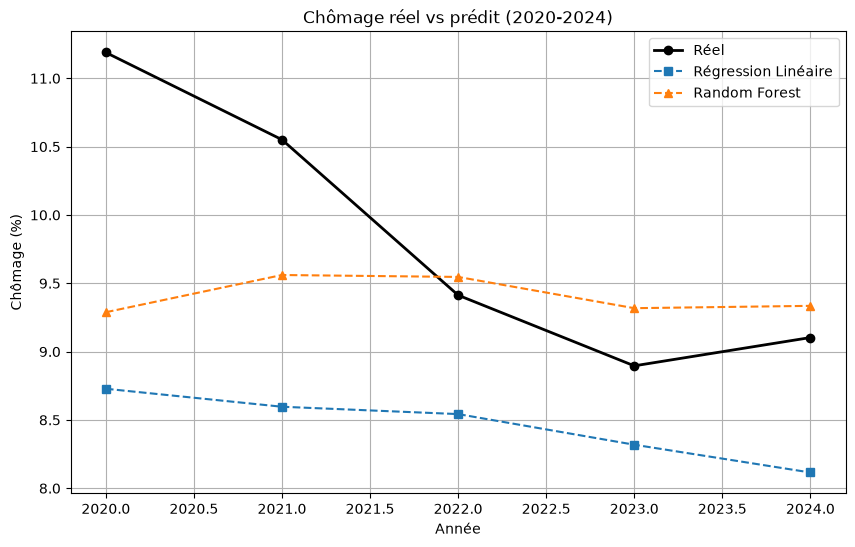

In [12]:
plt.figure(figsize=(10, 6))
plt.plot(y_test.index, y_test.values, label='Réel', marker='o', color='black', linewidth=2)
plt.plot(y_test.index, y_pred_lr, label='Régression Linéaire', marker='s', linestyle='--')
plt.plot(y_test.index, y_pred_rf, label='Random Forest', marker='^', linestyle='--')
plt.title("Chômage réel vs prédit (2020-2024)")
plt.xlabel("Année")
plt.ylabel("Chômage (%)")
plt.legend()
plt.grid(True)
plt.savefig('../images/predictions_comparaison.png', dpi=150)
plt.show()

pib_lag1              0.389118
pib_rolling3          0.360488
chomage_lag1          0.209069
inflation_lag1        0.029071
inflation_rolling3    0.012253
dtype: float64


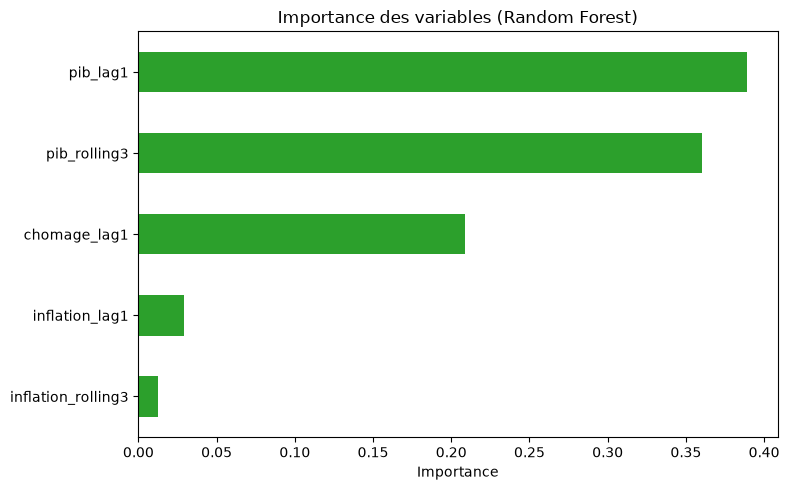

In [13]:
importances = pd.Series(model_rf.feature_importances_, index=features).sort_values(ascending=False)
print(importances)

plt.figure(figsize=(8, 5))
importances.plot(kind='barh', color='#2ca02c')
plt.title("Importance des variables (Random Forest)")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('../images/feature_importance.png', dpi=150)
plt.show()